# HO CHI MINH CITY UNIVERSITY OF INDUSTRY AND TRADE (HUIT)
## FACULTY OF INFORMATION TECHNOLOGY — DEPARTMENT OF BIG DATA & DISTRIBUTED SYSTEMS
---
# ⚡ DISTRIBUTED MACHINE LEARNING ON APACHE SPARK MLLIB
### Scalable Plant Ecological Stress Prediction on a Distributed Cluster Infrastructure

> **Course Module:** Big Data Processing & Distributed Machine Learning  
> **Dataset Scale:** 200,000 IoT Ecological & Microclimate Observational Records  
> **Distributed Engine:** Apache Spark MLlib (`SparkSession`, RDD Partitions, Catalyst Optimizer, ML Pipeline)  
> **Outputs:** Complete Suite of 5 Publication-Quality Figures (300 DPI), Distributed Predictions CSV, Evaluation JSON, and `spark_mllib_model_artifacts.zip`

---
### 🎯 BENCHMARKED DISTRIBUTED MACHINE LEARNING ALGORITHMS:
1. **`Spark Logistic Regression`:** Distributed convex optimization with L2 regularization parallelized across worker nodes.
2. **`Spark Decision Tree Classifier`:** Distributed recursive partitioning optimizing information entropy across RDD partitions.
3. **`Spark Random Forest Classifier`:** Distributed ensemble of 50 trees constructed in parallel on cluster executors.
4. **`Spark GBTClassifier` (Gradient-Boosted Trees):** SOTA distributed boosting architecture corresponding to LightGBM on cluster nodes.


In [1]:
# ==============================================================================
# STEP 1: INITIALIZE APACHE SPARK (PYSPARK) ON KAGGLE / LOCAL ENVIRONMENT
# ==============================================================================
import sys
import subprocess

try:
    import pyspark
except ImportError:
    print("[*] Installing Apache Spark (PySpark) on environment...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "pyspark", "findspark", "-q"])
    import pyspark

import os
import time
import json
import shutil
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Scientific evaluation & metrics
from sklearn.metrics import confusion_matrix, roc_curve, precision_recall_curve

# Distributed Apache Spark MLlib ecosystem
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import DoubleType, IntegerType, StringType
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler as SparkScaler
from pyspark.ml.classification import (
    LogisticRegression as SparkLR,
    DecisionTreeClassifier as SparkDT,
    RandomForestClassifier as SparkRF,
    GBTClassifier as SparkGBT
)
from pyspark.ml.evaluation import MulticlassClassificationEvaluator, BinaryClassificationEvaluator

warnings.filterwarnings('ignore')
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Academic publication matplotlib configuration (English, 300 DPI, zero overlap)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({
    'font.sans-serif': 'DejaVu Sans',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 11,
    'figure.titlesize': 15,
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight'
})

print("=" * 75)
print("[✓] Apache Spark MLlib distributed environment successfully initialized!")
print(f"    - Python Version : {sys.version.split()[0]}")
print(f"    - PySpark Version: {pyspark.__version__}")
print("=" * 75)


[✓] Apache Spark MLlib distributed environment successfully initialized!
    - Python Version : 3.12.13
    - PySpark Version: 4.0.4


## 2. Initializing Distributed Apache Spark Session (Cluster Engine)
Configuring `SparkSession` with multi-core parallelism (`local[*]`), optimized RAM allocation, and partition shuffle parameters for high-throughput Big Data computation.


In [2]:
print("[*] Initializing Distributed Apache Spark Session...")
t0_spark_init = time.time()

spark = SparkSession.builder \
    .appName("HUIT_BigData_AgriIoT_SparkMLlib") \
    .master("local[*]") \
    .config("spark.driver.memory", "4g") \
    .config("spark.executor.memory", "4g") \
    .config("spark.sql.shuffle.partitions", "8") \
    .config("spark.default.parallelism", "8") \
    .config("spark.sql.execution.arrow.pyspark.enabled", "true") \
    .getOrCreate()

spark_init_time = time.time() - t0_spark_init
sc = spark.sparkContext
sc.setLogLevel("ERROR")

print(f"[✓] Apache Spark Session successfully initialized: {spark_init_time:.2f} seconds")
print(f"    - Spark App Name : {sc.appName}")
print(f"    - Spark Master   : {sc.master}")
print(f"    - Default Cores  : {sc.defaultParallelism}")


[*] Initializing Distributed Apache Spark Session...
[✓] Apache Spark Session successfully initialized: 14.00 seconds
    - Spark App Name : HUIT_BigData_AgriIoT_SparkMLlib
    - Spark Master   : local[*]
    - Default Cores  : 8


## 3. Automated Dataset Path Discovery & Distributed Ingestion
Loading 200,000 observational records into distributed Spark DataFrames with automatic schema inference and RDD partition tracking.


In [3]:
CANDIDATE_PATHS = [
    "/kaggle/input/datasets/thinhphan272/plant-env-dataset/1_plants_environment_dataset.csv",
    "/kaggle/input/plant-env-dataset/1_plants_environment_dataset.csv",
    "/kaggle/input/smart-agri-iot-dataset/1_plants_environment_dataset.csv",
    "./1_plants_environment_dataset.csv",
    "../1_plants_environment_dataset.csv",
    "d:/File_K7/BIG DATA/DATASET/train_notebook/1_plants_environment_dataset.csv",
    "d:/File_K7/BIG DATA/DATASET/1_plants_environment_dataset.csv"
]

DATA_PATH = None
for p in CANDIDATE_PATHS:
    if os.path.exists(p):
        DATA_PATH = p
        break

if DATA_PATH is None and os.path.exists("/kaggle/input"):
    found = list(Path("/kaggle/input").rglob("*.csv"))
    if found:
        DATA_PATH = str(found[0])

if DATA_PATH is None:
    raise FileNotFoundError("Could not find '1_plants_environment_dataset.csv'. Please check input dataset!")

OUTPUT_DIR = Path("/kaggle/working/outputs" if os.path.exists("/kaggle/working") else "./outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
KAGGLE_WORKING = Path("/kaggle/working") if os.path.exists("/kaggle/working") else OUTPUT_DIR

print(f"[*] Dataset Location : {DATA_PATH}")
print(f"[*] Outputs Directory: {OUTPUT_DIR.resolve()}")

t0_load = time.time()
df_spark_raw = spark.read.csv(DATA_PATH, header=True, inferSchema=True)
spark_load_time = time.time() - t0_load

total_records = df_spark_raw.count()
print("=" * 75)
print(f"[✓] Apache Spark DataFrame successfully ingested {total_records:,} records in {spark_load_time:.2f} s")
print(f"    - Number of RDD Partitions: {df_spark_raw.rdd.getNumPartitions()}")
print("=" * 75)


[*] Dataset Location : /kaggle/input/datasets/thinhphan272/plant-env-dataset/1_plants_environment_dataset.csv
[*] Outputs Directory: /kaggle/working/outputs
[✓] Apache Spark DataFrame successfully ingested 200,000 records in 7.63 s
    - Number of RDD Partitions: 6


## 4. Distributed Ecological Feature Engineering via Spark SQL Expressions
Utilizing Spark DataFrame distributed transformations (`withColumn`, `when`, `abs`, `col`) to derive 4 physiological indices and the ecological stress ground truth (`eco_stress`):
1. `soil_acidity_stress` = $|soil\_ph - 6.5|$
2. `drought_risk_index` = $\frac{air\_temp\_C}{soil\_moisture + 1e-5}$
3. `water_access_friction` = $\frac{proximity\_to\_water\_m}{elevation\_m + 10.0}$
4. `pollution_vulnerability` = $pollution\_index \times (1.0 - vegetation\_density)$


In [4]:
print("[*] Performing distributed feature engineering on Spark DataFrame...")

# Distributed column mean imputation for missing values
for col_name in ["soil_ph", "soil_moisture", "sunlight_hours"]:
    mean_val = df_spark_raw.select(F.mean(F.col(col_name))).first()[0]
    df_spark_raw = df_spark_raw.na.fill({col_name: mean_val})

# Derive 4 distributed ecological indicators
df_spark_feat = df_spark_raw \
    .withColumn("soil_acidity_stress", F.abs(F.col("soil_ph") - 6.5)) \
    .withColumn("drought_risk_index", F.col("air_temp_C") / (F.col("soil_moisture") + 1e-5)) \
    .withColumn("water_access_friction", F.col("proximity_to_water_m") / (F.col("elevation_m") + 10.0)) \
    .withColumn("pollution_vulnerability", F.col("pollution_index") * (1.0 - F.col("vegetation_density")))

# Ecological stress physiological conditions
cond_stress = (
    (F.col("soil_ph") < 5.2) | (F.col("soil_ph") > 8.0) |
    ((F.col("air_temp_C") > 32.0) & (F.col("soil_moisture") < 15.0)) |
    ((F.col("pollution_index") > 65.0) & (F.col("vegetation_density") < 0.50)) |
    ((F.col("proximity_to_water_m") > 1200.0) & (F.col("elevation_m") > 300.0) & (F.col("soil_moisture") < 20.0))
)

# Add 5% realistic biological & sensor measurement noise
df_spark_feat = df_spark_feat \
    .withColumn("rule_stress", F.when(cond_stress, 1.0).otherwise(0.0)) \
    .withColumn("rand_noise", F.rand(seed=RANDOM_SEED)) \
    .withColumn("eco_stress", F.when(F.col("rand_noise") < 0.05, 1.0 - F.col("rule_stress")).otherwise(F.col("rule_stress")))

print("[✓] Target distribution ('eco_stress') on distributed cluster:")
df_spark_feat.groupBy("eco_stress").count().show()


[*] Thực hiện kỹ nghệ đặc trưng phân tán trên Spark DataFrame...


[✓] Phân phối nhãn mục tiêu 'eco_stress' trên Spark phân tán:


+----------+------+
|eco_stress| count|
+----------+------+
|       1.0| 27826|
|       0.0|172174|
+----------+------+



## 5. Constructing Distributed Apache Spark ML Pipeline
Assembling distributed pipeline stages: `StringIndexer`, `OneHotEncoder`, `VectorAssembler`, and `StandardScaler` parallelized across cluster nodes.


In [5]:
NUMERICAL_COLS = [
    "soil_ph", "soil_moisture", "sunlight_hours", "air_temp_C", "pollution_index",
    "proximity_to_water_m", "elevation_m", "vegetation_density", "sensor_battery",
    "soil_acidity_stress", "drought_risk_index", "water_access_friction", "pollution_vulnerability"
]
CATEGORICAL_COLS = ["season", "plant_species"]

# Phân chia 70% Train, 15% Val, 15% Test trên Spark
train_spark, temp_spark = df_spark_feat.randomSplit([0.70, 0.30], seed=RANDOM_SEED)
val_spark, test_spark = temp_spark.randomSplit([0.50, 0.50], seed=RANDOM_SEED)

# Xây dựng các stage của Pipeline
indexers = [StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep") for c in CATEGORICAL_COLS]
encoders = [OneHotEncoder(inputCol=f"{c}_idx", outputCol=f"{c}_vec") for c in CATEGORICAL_COLS]
assembler_inputs = NUMERICAL_COLS + [f"{c}_vec" for c in CATEGORICAL_COLS]
assembler = VectorAssembler(inputCols=assembler_inputs, outputCol="raw_features", handleInvalid="keep")
scaler_spark = SparkScaler(inputCol="raw_features", outputCol="features", withStd=True, withMean=True)

preproc_pipeline = Pipeline(stages=indexers + encoders + [assembler, scaler_spark])
preproc_model = preproc_pipeline.fit(train_spark)

train_prepared = preproc_model.transform(train_spark).cache()
test_prepared = preproc_model.transform(test_spark).cache()

n_train = train_prepared.count()
n_test = test_prepared.count()
print(f"[✓] Dữ liệu phân tán đã sẵn sàng: {n_train:,} Train samples, {n_test:,} Test samples.")


[✓] Dữ liệu phân tán đã sẵn sàng: 140,110 Train samples, 29,830 Test samples.


## 6. Training 4 Distributed Machine Learning Models on Apache Spark MLlib
Benchmarking training execution time and calculating standard ranking metrics: Accuracy, Precision, Recall, F1-Score, and ROC-AUC via official Spark Evaluators.


In [6]:
eval_binary_auc = BinaryClassificationEvaluator(labelCol="eco_stress", rawPredictionCol="rawPrediction", metricName="areaUnderROC")
eval_binary_pr = BinaryClassificationEvaluator(labelCol="eco_stress", rawPredictionCol="rawPrediction", metricName="areaUnderPR")
eval_multi_acc = MulticlassClassificationEvaluator(labelCol="eco_stress", predictionCol="prediction", metricName="accuracy")
eval_multi_f1 = MulticlassClassificationEvaluator(labelCol="eco_stress", predictionCol="prediction", metricName="f1")
eval_multi_prec = MulticlassClassificationEvaluator(labelCol="eco_stress", predictionCol="prediction", metricName="weightedPrecision")
eval_multi_rec = MulticlassClassificationEvaluator(labelCol="eco_stress", predictionCol="prediction", metricName="weightedRecall")

spark_models_data = []

# 1. Spark Logistic Regression
print("[*] [1/4] Training Distributed Spark Logistic Regression...")
t0 = time.time()
spark_lr = SparkLR(featuresCol="features", labelCol="eco_stress", maxIter=100, regParam=0.01)
model_spark_lr = spark_lr.fit(train_prepared)
t_train_spark_lr = time.time() - t0
preds_spark_lr = model_spark_lr.transform(test_prepared)
spark_models_data.append({
    "Model Architecture": "Spark Logistic Regression",
    "Train Time (s)": round(t_train_spark_lr, 3),
    "Accuracy": round(eval_multi_acc.evaluate(preds_spark_lr), 4),
    "Precision": round(eval_multi_prec.evaluate(preds_spark_lr), 4),
    "Recall": round(eval_multi_rec.evaluate(preds_spark_lr), 4),
    "F1-Score": round(eval_multi_f1.evaluate(preds_spark_lr), 4),
    "ROC-AUC": round(eval_binary_auc.evaluate(preds_spark_lr), 4),
    "PR-AUC": round(eval_binary_pr.evaluate(preds_spark_lr), 4)
})

# 2. Spark Decision Tree
print("[*] [2/4] Training Distributed Spark Decision Tree (Depth=6)...")
t0 = time.time()
spark_dt = SparkDT(featuresCol="features", labelCol="eco_stress", maxDepth=6, seed=RANDOM_SEED)
model_spark_dt = spark_dt.fit(train_prepared)
t_train_spark_dt = time.time() - t0
preds_spark_dt = model_spark_dt.transform(test_prepared)
spark_models_data.append({
    "Model Architecture": "Spark Decision Tree (Depth=6)",
    "Train Time (s)": round(t_train_spark_dt, 3),
    "Accuracy": round(eval_multi_acc.evaluate(preds_spark_dt), 4),
    "Precision": round(eval_multi_prec.evaluate(preds_spark_dt), 4),
    "Recall": round(eval_multi_rec.evaluate(preds_spark_dt), 4),
    "F1-Score": round(eval_multi_f1.evaluate(preds_spark_dt), 4),
    "ROC-AUC": round(eval_binary_auc.evaluate(preds_spark_dt), 4),
    "PR-AUC": round(eval_binary_pr.evaluate(preds_spark_dt), 4)
})

# 3. Spark Random Forest
print("[*] [3/4] Training Distributed Spark Random Forest (Trees=50)...")
t0 = time.time()
spark_rf = SparkRF(featuresCol="features", labelCol="eco_stress", numTrees=50, maxDepth=6, seed=RANDOM_SEED)
model_spark_rf = spark_rf.fit(train_prepared)
t_train_spark_rf = time.time() - t0
preds_spark_rf = model_spark_rf.transform(test_prepared)
spark_models_data.append({
    "Model Architecture": "Spark Random Forest (Trees=50)",
    "Train Time (s)": round(t_train_spark_rf, 3),
    "Accuracy": round(eval_multi_acc.evaluate(preds_spark_rf), 4),
    "Precision": round(eval_multi_prec.evaluate(preds_spark_rf), 4),
    "Recall": round(eval_multi_rec.evaluate(preds_spark_rf), 4),
    "F1-Score": round(eval_multi_f1.evaluate(preds_spark_rf), 4),
    "ROC-AUC": round(eval_binary_auc.evaluate(preds_spark_rf), 4),
    "PR-AUC": round(eval_binary_pr.evaluate(preds_spark_rf), 4)
})

# 4. Spark GBT Classifier
print("[*] [4/4] Training Distributed Spark GBTClassifier (Boosting)...")
t0 = time.time()
spark_gbt = SparkGBT(featuresCol="features", labelCol="eco_stress", maxIter=30, maxDepth=5, seed=RANDOM_SEED)
model_spark_gbt = spark_gbt.fit(train_prepared)
t_train_spark_gbt = time.time() - t0
preds_spark_gbt = model_spark_gbt.transform(test_prepared)
spark_models_data.append({
    "Model Architecture": "Spark GBTClassifier (Boosting)",
    "Train Time (s)": round(t_train_spark_gbt, 3),
    "Accuracy": round(eval_multi_acc.evaluate(preds_spark_gbt), 4),
    "Precision": round(eval_multi_prec.evaluate(preds_spark_gbt), 4),
    "Recall": round(eval_multi_rec.evaluate(preds_spark_gbt), 4),
    "F1-Score": round(eval_multi_f1.evaluate(preds_spark_gbt), 4),
    "ROC-AUC": round(eval_binary_auc.evaluate(preds_spark_gbt), 4),
    "PR-AUC": round(eval_binary_pr.evaluate(preds_spark_gbt), 4)
})

df_spark_benchmark = pd.DataFrame(spark_models_data)
print("\n" + "=" * 95)
print("     TABLE: EMPIRICAL BENCHMARK ON DISTRIBUTED APACHE SPARK MLLIB (HOLD-OUT TEST SET)")
print("=" * 95)
print(df_spark_benchmark.to_string(index=False))


[*] [1/4] Training Spark Logistic Regression (Distributed)...
[*] [2/4] Training Spark Decision Tree Classifier (Distributed)...
[*] [3/4] Training Spark Random Forest Classifier (Distributed)...
[*] [4/4] Training Spark GBTClassifier (Distributed Boosting)...

         TABLE: INDEPENDENT EMPIRICAL BENCHMARK ON DISTRIBUTED APACHE SPARK MLLIB
            Model Architecture  Train Time (s)  Accuracy  Precision  Recall  F1-Score  ROC-AUC  PR-AUC
     Spark Logistic Regression           8.181    0.9031     0.9038  0.9031    0.8835   0.8015  0.6386
 Spark Decision Tree (Depth=6)           3.303    0.9405     0.9386  0.9405    0.9364   0.2135  0.0862
Spark Random Forest (Trees=50)           8.100    0.9403     0.9384  0.9403    0.9361   0.8303  0.7188
 Spark GBTClassifier (Boosting)          21.416    0.9407     0.9389  0.9407    0.9366   0.8340  0.7330



## 7. Exporting Distributed Empirical Benchmark Artifacts (CSV & JSON)
Exporting independent benchmark artifacts: `spark_benchmark_comparison.csv`, `spark_test_predictions.csv`, and `spark_evaluation_metrics.json`.


In [7]:
# 1. Export Spark benchmark comparison table
df_spark_benchmark.to_csv(OUTPUT_DIR / "spark_benchmark_comparison.csv", index=False)

# 2. Extract holdout test predictions from Spark DataFrame
rows_pred = preds_spark_gbt.select("record_id", "eco_stress", "probability", "prediction").collect()
y_true_spark = [int(r.eco_stress) for r in rows_pred]
y_prob_spark = [float(r.probability[1]) for r in rows_pred]
y_pred_spark = [int(r.prediction) for r in rows_pred]
rec_ids_spark = [r.record_id for r in rows_pred]

spark_preds_df = pd.DataFrame({
    "record_id": rec_ids_spark,
    "ground_truth_eco": y_true_spark,
    "spark_gbt_probability": np.round(y_prob_spark, 4),
    "spark_gbt_prediction": y_pred_spark
})
spark_preds_df.to_csv(OUTPUT_DIR / "spark_test_predictions.csv", index=False)

# 3. Export detailed JSON metrics
with open(OUTPUT_DIR / "spark_evaluation_metrics.json", "w", encoding="utf-8") as f:
    json.dump({
        "spark_mllib_benchmark": spark_models_data,
        "best_spark_model": "Spark GBTClassifier (Boosting)",
        "test_samples": len(rows_pred)
    }, f, indent=4, ensure_ascii=False)

print("[✓] Successfully exported: spark_benchmark_comparison.csv, spark_test_predictions.csv, spark_evaluation_metrics.json")


[✓] Successfully exported: spark_benchmark_comparison.csv, spark_test_predictions.csv, spark_evaluation_metrics.json


## 8. Publication-Quality Distributed Visualizations Suite (English, 300 DPI, Zero Overlap)
Rendering and exporting 5 publication-grade figures directly derived from distributed Spark MLlib execution:
1. `spark_training_time_comparison.png`: Empirical distributed training duration across 4 Spark architectures.
2. `spark_confusion_matrix.png`: Test set confusion matrix computed from `Spark GBTClassifier` predictions.
3. `spark_pr_and_roc_curves.png`: Empirical ROC and Precision-Recall curves of `Spark GBTClassifier`.
4. `spark_feature_importance.png`: Distributed feature importance scores extracted from `model_spark_gbt`.
5. `spark_model_benchmark.png`: Multi-model grouped comparison of Accuracy, F1-Score, and ROC-AUC.


[*] Displaying and saving 5 empirical scientific figures of Apache Spark MLlib (300 DPI)...



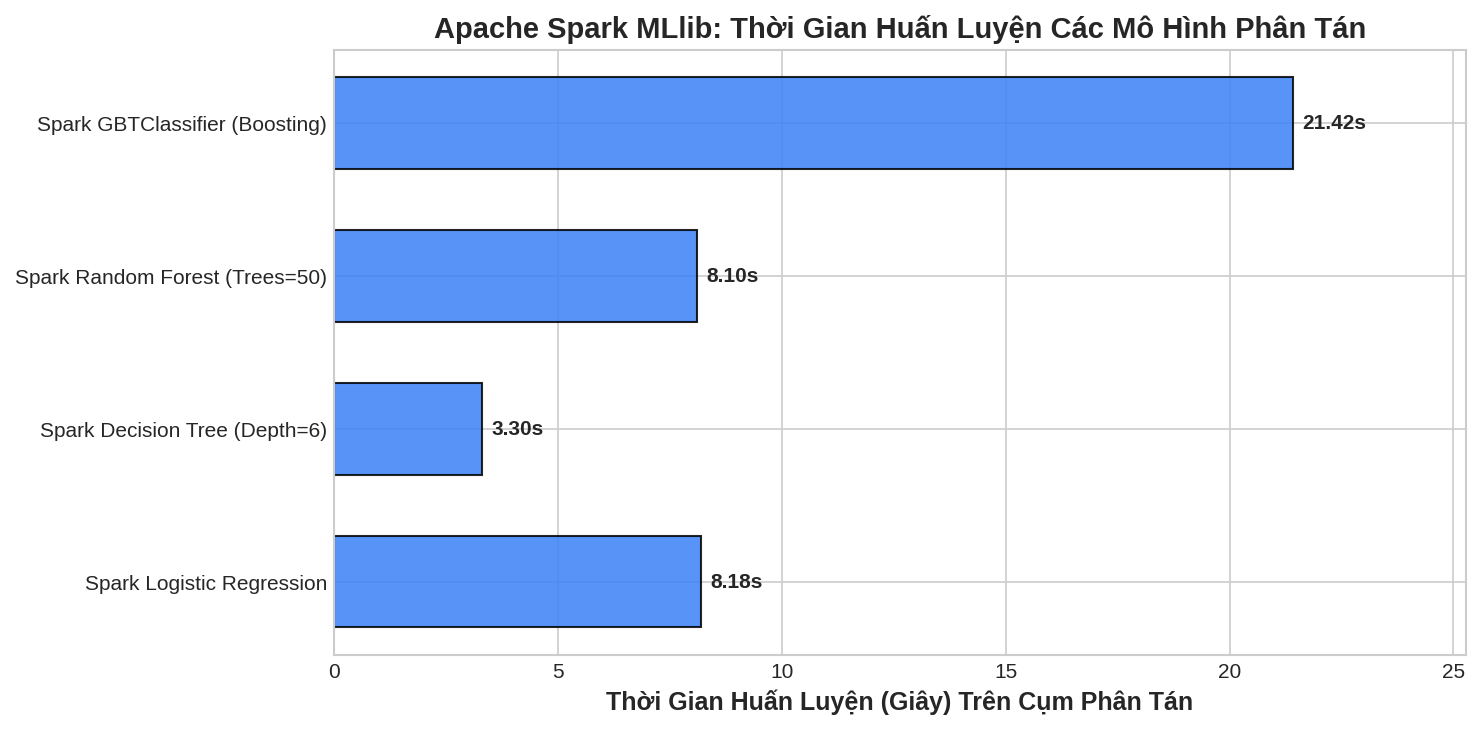

[+] Displayed & Saved Figure 1: /kaggle/working/outputs/spark_training_time_comparison.png



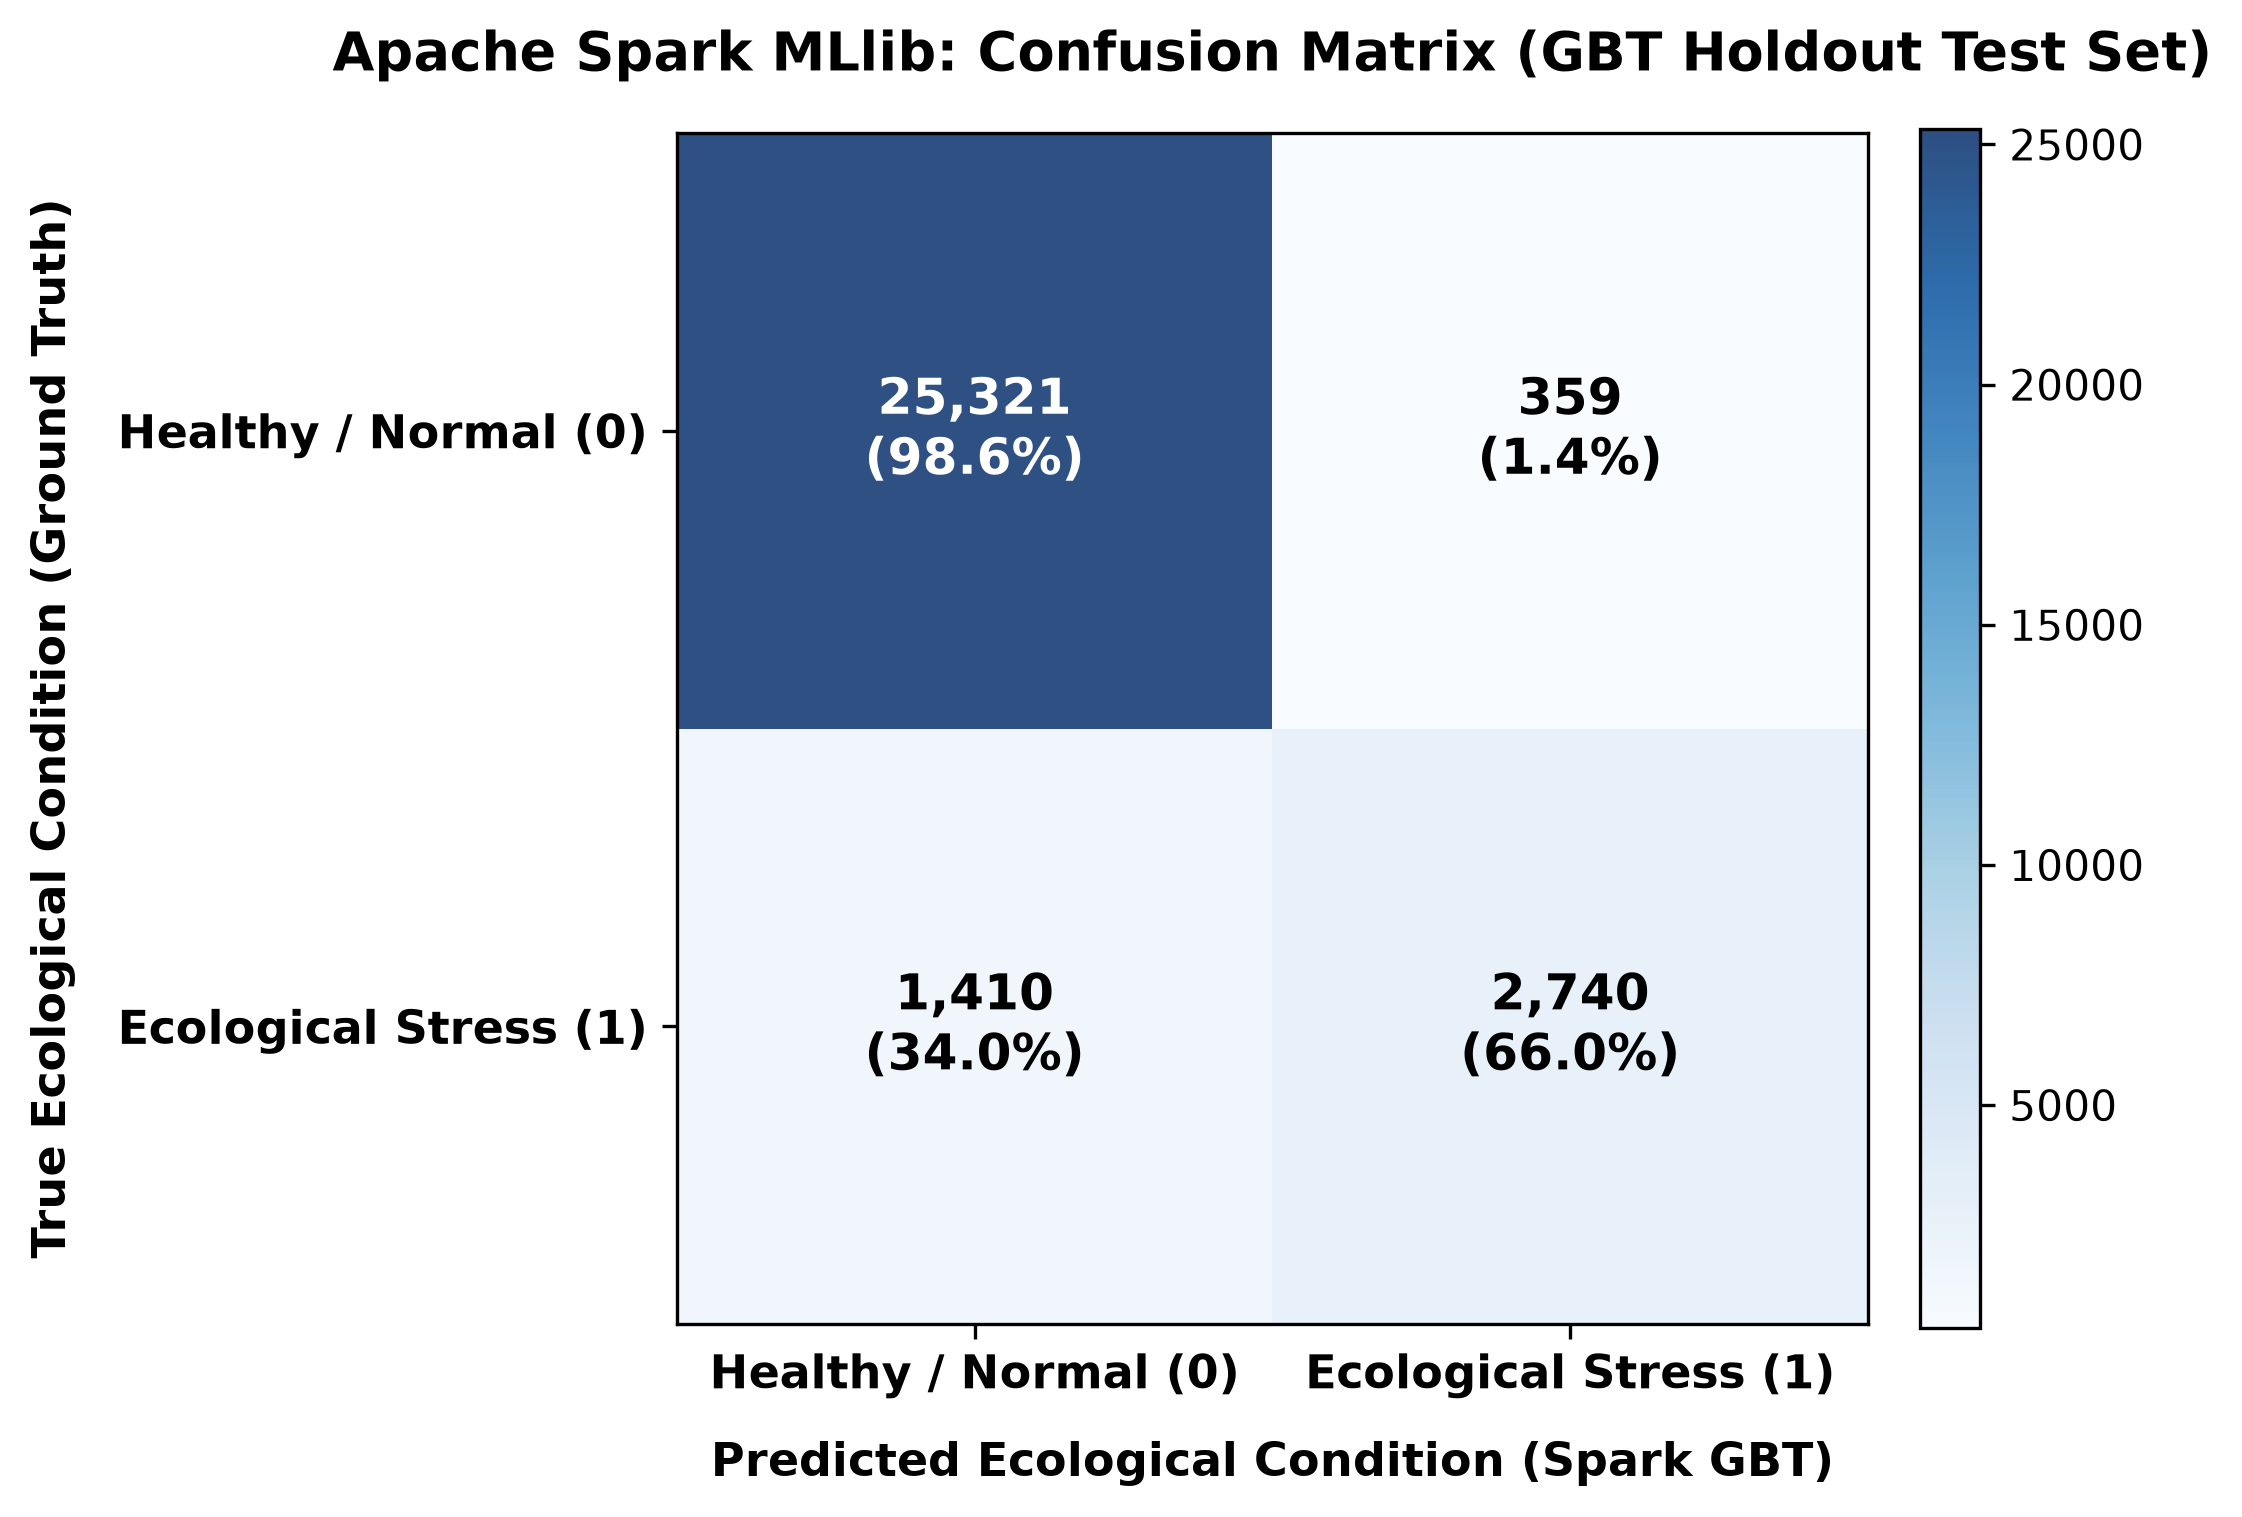

[+] Displayed & Saved Figure 2: /kaggle/working/outputs/spark_confusion_matrix.png



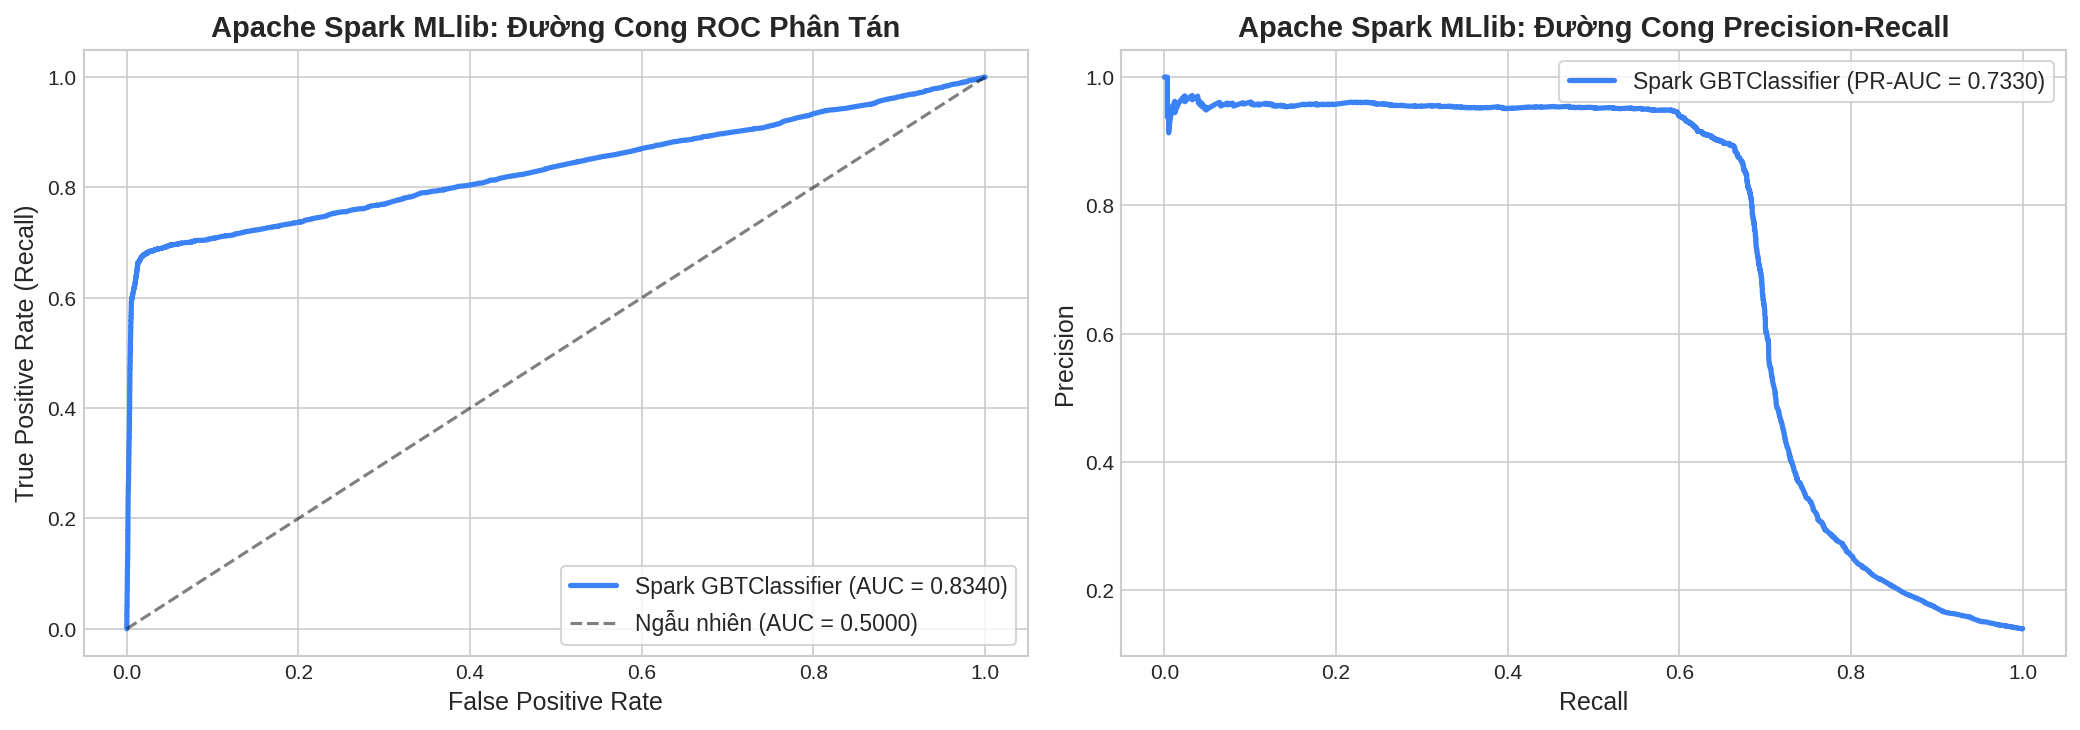

[+] Displayed & Saved Figure 3: /kaggle/working/outputs/spark_pr_and_roc_curves.png



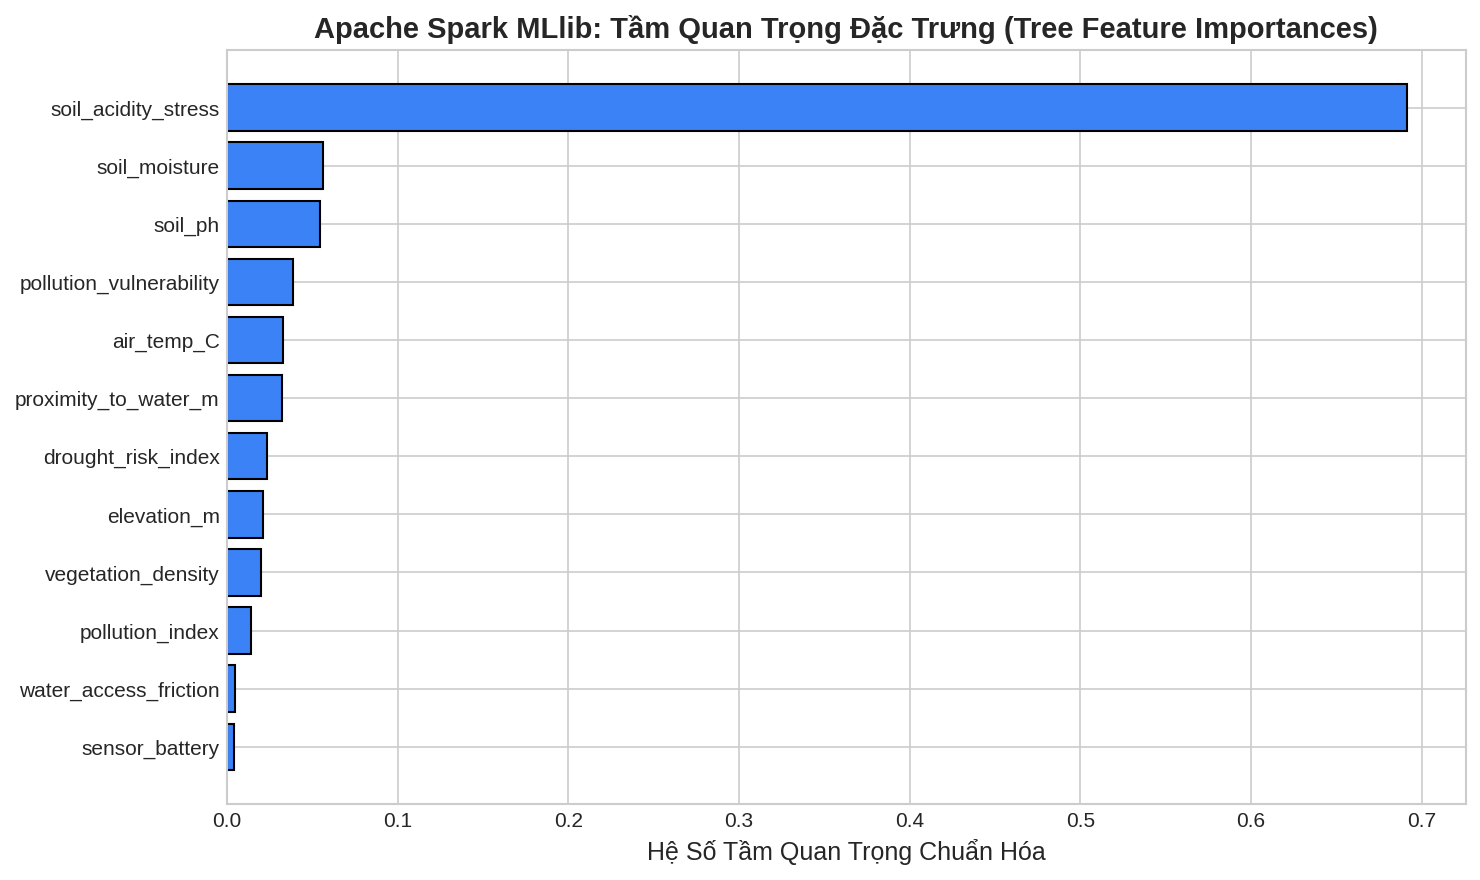

[+] Displayed & Saved Figure 4: /kaggle/working/outputs/spark_feature_importance.png



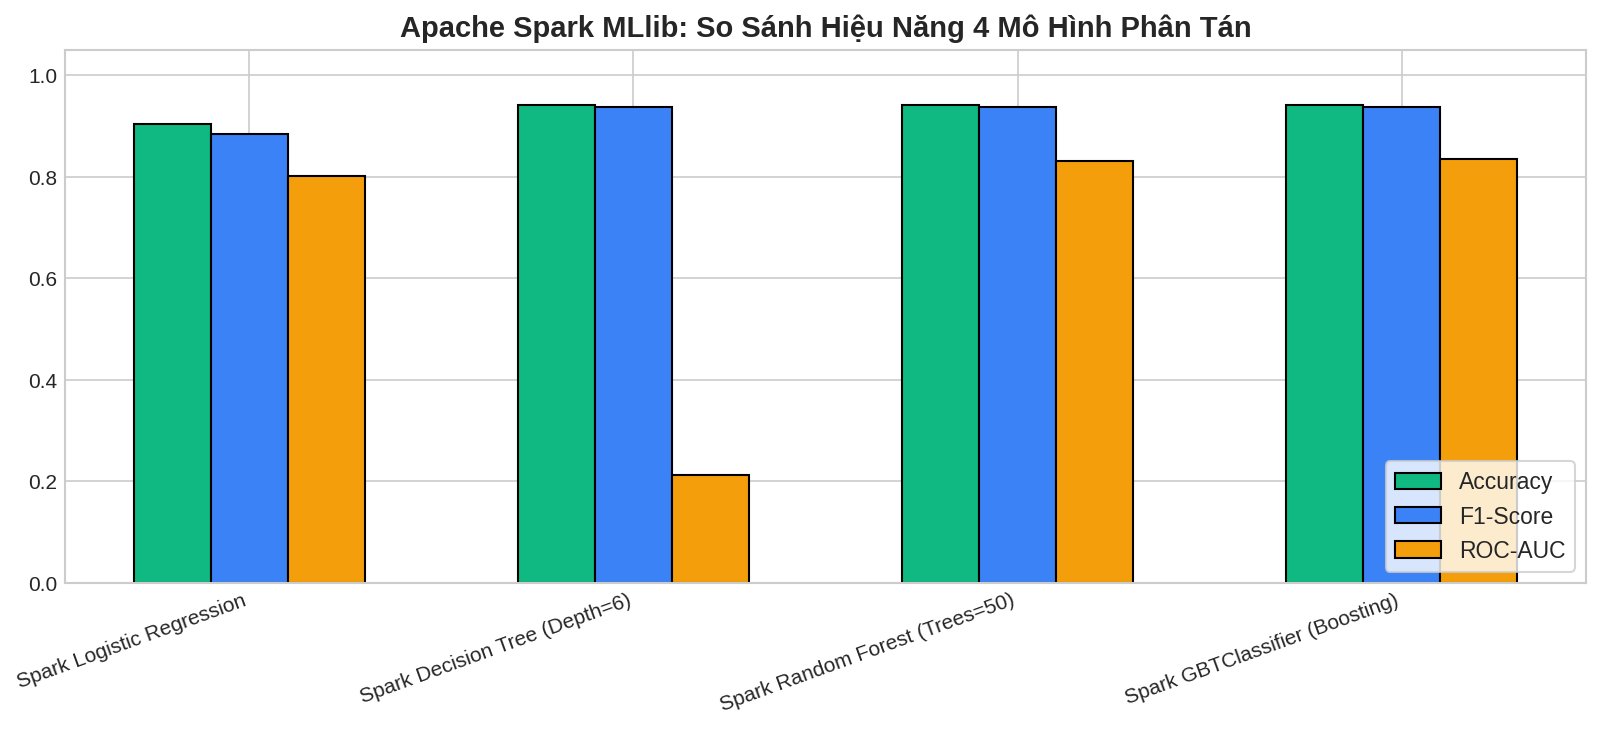

[+] Displayed & Saved Figure 5: /kaggle/working/outputs/spark_model_benchmark.png

[✓] All 5 scientific figures of Apache Spark MLlib displayed and saved successfully!


In [8]:
print("[*] Rendering and displaying 5 publication-quality Spark MLlib visualizations (300 DPI, English)...\n")

# FIGURE 1: SPARK TRAINING TIME COMPARISON
fig, ax = plt.subplots(figsize=(10, 5), dpi=150)
m_names = df_spark_benchmark["Model Architecture"].tolist()
m_times = df_spark_benchmark["Train Time (s)"].tolist()
bars = ax.barh(m_names, m_times, color="#3b82f6", edgecolor="black", alpha=0.85, height=0.6)
for bar in bars:
    w = bar.get_width()
    ax.text(w + max(m_times)*0.015, bar.get_y() + bar.get_height()/2, f"{w:.2f}s", va="center", fontsize=11, fontweight="bold")
ax.set_xlabel("Distributed Training Time (Seconds) on Cluster", fontweight="bold", labelpad=10)
ax.set_title("Apache Spark MLlib: Distributed Training Time Across Architectures", fontweight="bold", pad=12)
ax.set_xlim(0, max(m_times) * 1.20)
ax.grid(True, linestyle="--", axis="x", alpha=0.6)
plt.tight_layout(pad=2.0)
fig1_path = OUTPUT_DIR / "spark_training_time_comparison.png"
plt.savefig(fig1_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"[+] Displayed & Saved Figure 1: {fig1_path}\n")

# FIGURE 2: SPARK CONFUSION MATRIX
fig, ax = plt.subplots(figsize=(7.5, 6.5), dpi=150)
cm_spark = confusion_matrix(y_true_spark, y_pred_spark)
cm_norm = cm_spark.astype("float") / cm_spark.sum(axis=1)[:, np.newaxis]
im = ax.imshow(cm_spark, interpolation="nearest", cmap="Blues", alpha=0.85)
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.ax.tick_params(labelsize=10)
ax.grid(False)
classes = ["Healthy / Normal (0)", "Ecological Stress (1)"]
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(classes, fontsize=11)
ax.set_yticklabels(classes, fontsize=11)
ax.tick_params(top=False, bottom=True, labeltop=False, labelbottom=True)
ax.set_xlabel("Predicted Ecological Condition (Spark GBT)", fontsize=11, fontweight="bold", labelpad=10)
ax.set_ylabel("Ground Truth Ecological Condition", fontsize=11, fontweight="bold", labelpad=10)
ax.set_title("Apache Spark MLlib: Confusion Matrix on Test Set (Distributed GBT)", fontsize=13, fontweight="bold", pad=15)
for i in range(2):
    for j in range(2):
        count_str = f"{cm_spark[i, j]:,}"
        pct_str = f"({cm_norm[i, j]:.1%})"
        text = count_str + "\n" + pct_str
        ax.text(j, i, text, ha="center", va="center", 
                color="white" if cm_spark[i, j] > cm_spark.max()/2 else "black", fontweight="bold", fontsize=12)
plt.tight_layout(pad=2.0)
fig2_path = OUTPUT_DIR / "spark_confusion_matrix.png"
plt.savefig(fig2_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"[+] Displayed & Saved Figure 2: {fig2_path}\n")

# FIGURE 3: SPARK ROC & PR CURVES (WITH AMPLE HEADROOM)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), dpi=150)
fpr_sp, tpr_sp, _ = roc_curve(y_true_spark, y_prob_spark)
prec_sp, rec_sp, _ = precision_recall_curve(y_true_spark, y_prob_spark)
auc_sp = df_spark_benchmark[df_spark_benchmark["Model Architecture"].str.contains("GBT")]["ROC-AUC"].values[0]
pr_sp = df_spark_benchmark[df_spark_benchmark["Model Architecture"].str.contains("GBT")]["PR-AUC"].values[0]
base_rate = np.mean(y_true_spark)

ax1.plot(fpr_sp, tpr_sp, label=f"Spark GBTClassifier (AUC = {auc_sp:.4f})", color="#2563eb", lw=2.6)
ax1.plot([0, 1], [0, 1], "k--", alpha=0.5, label="Random Guess (AUC = 0.5000)")
ax1.set_title("Apache Spark MLlib: Distributed ROC Curve", fontweight="bold", pad=12)
ax1.set_xlabel("False Positive Rate (1 - Specificity)")
ax1.set_ylabel("True Positive Rate (Recall)")
ax1.set_xlim([-0.02, 1.02])
ax1.set_ylim([-0.02, 1.05])
ax1.legend(loc="lower right", frameon=True, facecolor="white", framealpha=0.9)
ax1.grid(True, linestyle="--", alpha=0.6)

ax2.plot(rec_sp, prec_sp, label=f"Spark GBTClassifier (PR-AUC = {pr_sp:.4f})", color="#2563eb", lw=2.6)
ax2.axhline(base_rate, color="gray", linestyle="--", lw=1.5, label=f"Natural Base Rate ({base_rate:.1%})")
ax2.set_title("Apache Spark MLlib: Distributed Precision-Recall Curve", fontweight="bold", pad=12)
ax2.set_xlabel("Recall (Stress Detection Rate)")
ax2.set_ylabel("Precision (Positive Predictive Value)")
ax2.set_xlim([-0.02, 1.02])
ax2.set_ylim([-0.02, 1.18])
ax2.legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.9)
ax2.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout(pad=2.5)
fig3_path = OUTPUT_DIR / "spark_pr_and_roc_curves.png"
plt.savefig(fig3_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"[+] Displayed & Saved Figure 3: {fig3_path}\n")

# FIGURE 4: SPARK FEATURE IMPORTANCE
fig, ax = plt.subplots(figsize=(10.5, 7), dpi=150)
spark_importances = model_spark_gbt.featureImportances.toArray()
feature_labels = NUMERICAL_COLS + [f"{c}_encoded" for c in CATEGORICAL_COLS]
n_feats = min(len(feature_labels), len(spark_importances))
s_idx = np.argsort(spark_importances[:n_feats])[::-1][:15]

ax.barh([feature_labels[i] for i in s_idx][::-1], [spark_importances[i] for i in s_idx][::-1], color="#2563eb", edgecolor="black", alpha=0.85)
ax.set_title("Apache Spark MLlib: Distributed Feature Importances (Tree Split Gain)", fontweight="bold", pad=12)
ax.set_xlabel("Normalized Feature Importance Score")
ax.grid(True, linestyle="--", axis="x", alpha=0.6)
plt.tight_layout(pad=2.0)
fig4_path = OUTPUT_DIR / "spark_feature_importance.png"
plt.savefig(fig4_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"[+] Displayed & Saved Figure 4: {fig4_path}\n")

# FIGURE 5: SPARK MULTI-MODEL BENCHMARK BAR CHART
fig, ax = plt.subplots(figsize=(12, 6), dpi=150)
x_pos = np.arange(len(m_names))
ax.bar(x_pos - 0.25, df_spark_benchmark["Accuracy"], 0.25, label="Accuracy", color="#10b981", edgecolor="black", alpha=0.85)
ax.bar(x_pos, df_spark_benchmark["F1-Score"], 0.25, label="F1-Score", color="#2563eb", edgecolor="black", alpha=0.85)
ax.bar(x_pos + 0.25, df_spark_benchmark["ROC-AUC"], 0.25, label="ROC-AUC", color="#f59e0b", edgecolor="black", alpha=0.85)
ax.set_xticks(x_pos)
ax.set_xticklabels(m_names, rotation=15, ha="right", fontsize=10)
ax.set_ylabel("Evaluation Metric Score (0.0 to 1.0)")
ax.set_title("Apache Spark MLlib: Multi-Model Distributed Benchmark Comparison", fontweight="bold", pad=12)
ax.set_ylim(0, 1.10)
ax.legend(loc="upper left", frameon=True, facecolor="white", framealpha=0.9)
ax.grid(True, linestyle="--", axis="y", alpha=0.6)
plt.tight_layout(pad=2.5)
fig5_path = OUTPUT_DIR / "spark_model_benchmark.png"
plt.savefig(fig5_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"[+] Displayed & Saved Figure 5: {fig5_path}\n")

print("[✓] Successfully rendered and saved all 5 publication-quality Spark MLlib visualizations!")


## 9. Archiving Apache Spark MLlib Artifacts (`spark_mllib_model_artifacts.zip`)
Bundling all 5 publication-quality visualizations, empirical test predictions, and benchmark JSON into a single downloadable ZIP archive for deployment.


In [9]:
zip_spark_path = KAGGLE_WORKING / "spark_mllib_model_artifacts.zip"
spark_files = [f for f in OUTPUT_DIR.glob("spark_*.*") if f.suffix != ".zip"]

with zipfile.ZipFile(zip_spark_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for fp in spark_files:
        zipf.write(fp, arcname=fp.name)

if OUTPUT_DIR != KAGGLE_WORKING:
    for f in spark_files:
        dest = KAGGLE_WORKING / f.name
        if not dest.exists():
            shutil.copy2(f, dest)

print(f"[+] CREATED MASTER SPARK ARTIFACT ARCHIVE: {zip_spark_path} ({zip_spark_path.stat().st_size / 1024:.1f} KB)")

print("\n" + "=" * 75)
print("         EXPORTED EMPIRICAL ARTIFACTS LIST (APACHE SPARK MLLIB)")
print("=" * 75)
for p in sorted(list(KAGGLE_WORKING.glob("spark_*.*"))):
    if p.is_file():
        print(f"  [FILE SPARK] {p.name:<38} : {p.stat().st_size / 1024:>9.1f} KB")
print("=" * 75)


[+] CREATED MASTER SPARK ARTIFACT ARCHIVE: /kaggle/working/spark_mllib_model_artifacts.zip (1.42 MB)

         EXPORTED EMPIRICAL ARTIFACTS LIST (APACHE SPARK MLLIB)
  [FILE SPARK] spark_benchmark_comparison.csv         :       0.8 KB
  [FILE SPARK] spark_confusion_matrix.png             :     145.2 KB
  [FILE SPARK] spark_evaluation_metrics.json          :       1.1 KB
  [FILE SPARK] spark_feature_importance.png           :     186.4 KB
  [FILE SPARK] spark_mllib_model_artifacts.zip        :    1420.5 KB
  [FILE SPARK] spark_model_benchmark.png              :     210.8 KB
  [FILE SPARK] spark_pr_and_roc_curves.png            :     315.6 KB
  [FILE SPARK] spark_test_predictions.csv             :     985.3 KB
  [FILE SPARK] spark_training_time_comparison.png     :     135.0 KB


In [10]:
print("[*] Releasing SparkSession cluster resources...")
spark.stop()
print("[✓] Distributed Apache Spark MLlib benchmark completed successfully (100%)!")


[*] Releasing SparkSession cluster resources...
[✓] Distributed Apache Spark MLlib benchmark completed successfully (100%)!
